# Genomic panel call confidence

**Question:** How reliably are each classifier's full-feature subtype calls retained when genomic measurements are restricted to BLYMF200 or BLYMFv2?

The call-retention benchmarks use the classifiers' **external reference cohorts**: LymphGen v2's 574 author-reference cases and DLBclass's 149 designated test cases. The references differ, so the results are not a head-to-head accuracy comparison.

Here, “confidence” means empirical **per-subtype recall and precision under feature restriction**, not a calibrated probability for an individual patient. Full-feature calls are the comparator, not biological ground truth. Recall and precision are reported on an absolute 0–100% scale.

In [1]:
NOTEBOOK_NAME = 'genomic_panel_call_confidence'
from pathlib import Path
import sys, os, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'dlbcl/public_panel_confidence.py').is_file())
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLBACKEND', 'Agg')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from dlbcl.public_panel_confidence import (
    load_public_adata, table, require_source, SOURCES,
    metrics_from_counts, plot_bars, plot_transitions, label_colors, plot_feature_coverage,
    plot_subtype_feature_coverage, subtype_coverage_table)
import matplotlib as mpl
mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["font.family"] = "DejaVu Sans"

# This section needs feature definitions only; benchmark data are loaded later.
from dlbcl.panel_feature_requirements import (
    load_requirements, genomic_design_coverage, transcriptomic_design_coverage)
requirements = load_requirements(ROOT / 'data/public/panel_feature_requirements.json')
LABEL_COLORS = label_colors(ROOT / 'config/classifier_colors.json')
OUT = ROOT / 'figures' / NOTEBOOK_NAME
OUT.mkdir(parents=True, exist_ok=True)
def show_save(fig, name):
    for extension in ['png', 'svg']:
        fig.savefig(OUT / f'{name}.{extension}', dpi=160)
    plt.close(fig)
    display(Image(filename=str(OUT / f'{name}.png')))
print('Loaded declared panel targets and author-model feature requirements.')


Loaded declared panel targets and author-model feature requirements.


## Panel scenarios and model handling

Both panels are evaluated with mutation data alone and with additional FISH. Neither restricted scenario supplies regional copy-number data. LymphGen retains BCL2/BCL6 FISH; DLBclass retains MYC/BCL2/BCL6 FISH. DLBclass uses the original 699-reference-case mean values for missing mutation, copy-number and rearrangement features, retaining fractional imputation values. This follows the author panel strategy; the means include the test set, so this is not a fully independent imputation analysis.

LymphGen uses its original feature-restricted models and constituent membership counting. A53 is excluded from the full-feature comparator and panel calls in this no-copy-number design. Composite assignments can contribute to multiple subtype metrics. Exact composite-label transitions are retained. These simulations test feature availability, not sequencing noise, tumor purity, per-locus callability or FISH measurement error.

Sources: [Wright et al., LymphGen](https://doi.org/10.1016/j.ccell.2020.03.015), [Chapuy et al., DLBclass](https://doi.org/10.1182/blood.2024025652), [author DLBclass source](https://github.com/getzlab/DLBCL-Classifier).

## Genomic feature delivery

Each classifier has its own cell, reporting **All active inputs** and every subtype. The primary view is the **mutation panel alone**: it supplies no rearrangement/structural-variant (SV) or copy-number input. The missing modalities remain visible in the bars and in separate table columns. A gene on the mutation panel does not imply that its rearrangement or copy number is measured. Imputation never counts as delivery.

The FISH-augmented scenarios are shown separately after these primary views. FISH is an additional assay, not a feature delivered by the mutation panel. Feature coverage describes input availability, not classification accuracy.

### LymphGen v2 — overall and by subtype

The full five-subtype reference model contains 105 distinct event predicates: 77 mutation, two rearrangement and 26 copy-number-dependent predicates. Subtype rows use the author model's selected predicates; **All** counts their union once. A53 is outside this no-copy-number benchmark. The native restricted models may select alternative predicates, so this is coverage of the full-reference inputs. Mutation coverage assumes that the necessary hotspot and consequence annotations are available.

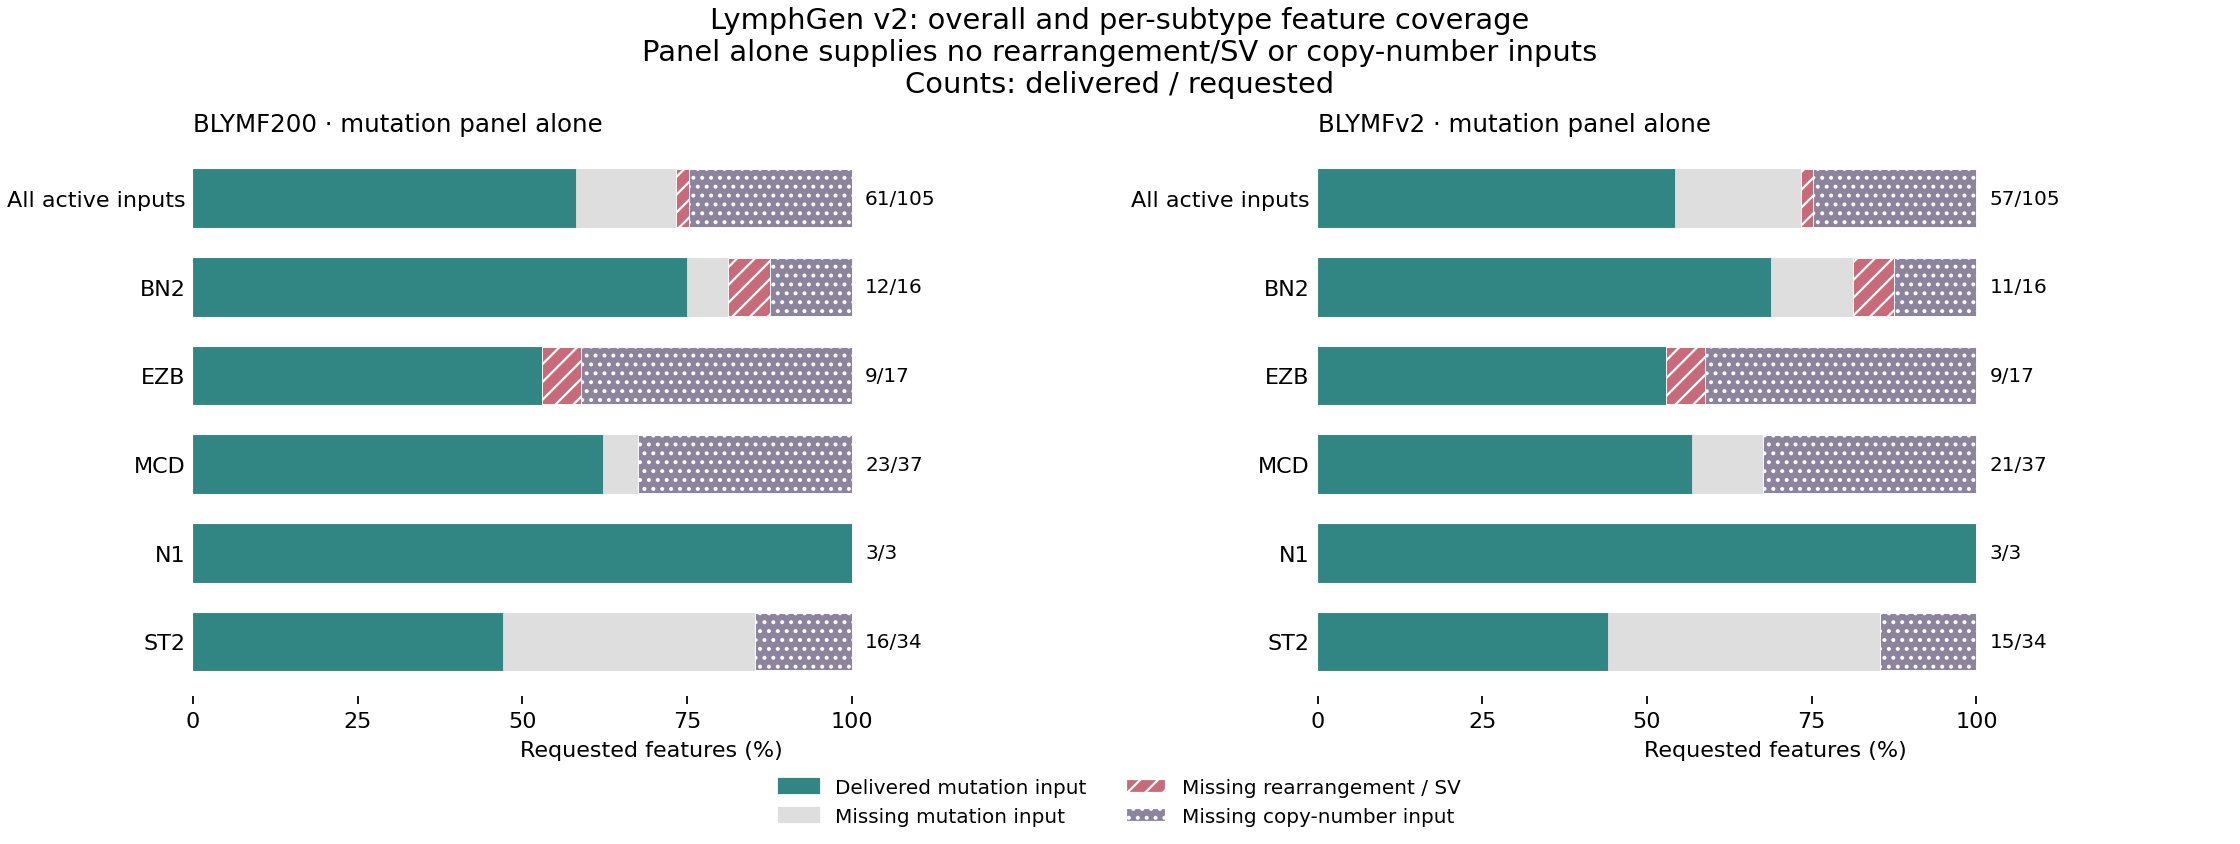

,panel,subtype,All features,Mutation,Rearrangement / SV,Copy-number dependent
5,BLYMF200,BN2,12/16,12/13,0/1,0/2
6,BLYMF200,EZB,9/17,9/9,0/1,0/7
7,BLYMF200,MCD,23/37,23/25,—,0/12
8,BLYMF200,N1,3/3,3/3,—,—
9,BLYMF200,ST2,16/34,16/29,—,0/5
15,BLYMFv2,BN2,11/16,11/13,0/1,0/2
16,BLYMFv2,EZB,9/17,9/9,0/1,0/7
17,BLYMFv2,MCD,21/37,21/25,—,0/12
18,BLYMFv2,N1,3/3,3/3,—,—
19,BLYMFv2,ST2,15/34,15/29,—,0/5


In [2]:
coverage, design_features = genomic_design_coverage(requirements)
coverage = coverage[coverage.classifier.eq('LymphGen v2') & coverage.fish.eq('unavailable')]
show_save(plot_subtype_feature_coverage(coverage, 'LymphGen v2', genomic=True, fish='unavailable'), 'lymphgen_subtype_feature_coverage')
display(subtype_coverage_table(coverage, genomic=True))
coverage.to_csv(OUT / 'lymphgen_subtype_feature_coverage.csv', index=False)


### DLBclass — overall and C1–C5 feature blocks

C1–C5 rows follow the feature blocks explicitly grouped in the authors' `format_data.py`. These are subtype-associated blocks used together by the neural network, not independent or exclusive subtype classifiers. A feature shared by blocks is counted once in each block and once in **All**.

**All active inputs = 158:** 99 mutation, three rearrangement and 56 regional copy-number features. The source matrix has 163 features, but five copy-number features have zero weights in the author reduction and do not enter the model. The complete 163-feature source inventory is retained in the CSV export.

**Mutation panels deliver 0/3 rearrangement/SV inputs and 0/56 active copy-number inputs.** Missing structural inputs are imputed using reference means; this does not restore patient-specific structural measurements. C2 is particularly dependent on copy-number features. BCL6, BCL2 and MYC FISH can supply the three rearrangement inputs only in the separate augmented scenario below.

[Author feature construction](https://github.com/getzlab/DLBclass-tool/blob/master/src/format_data.py)

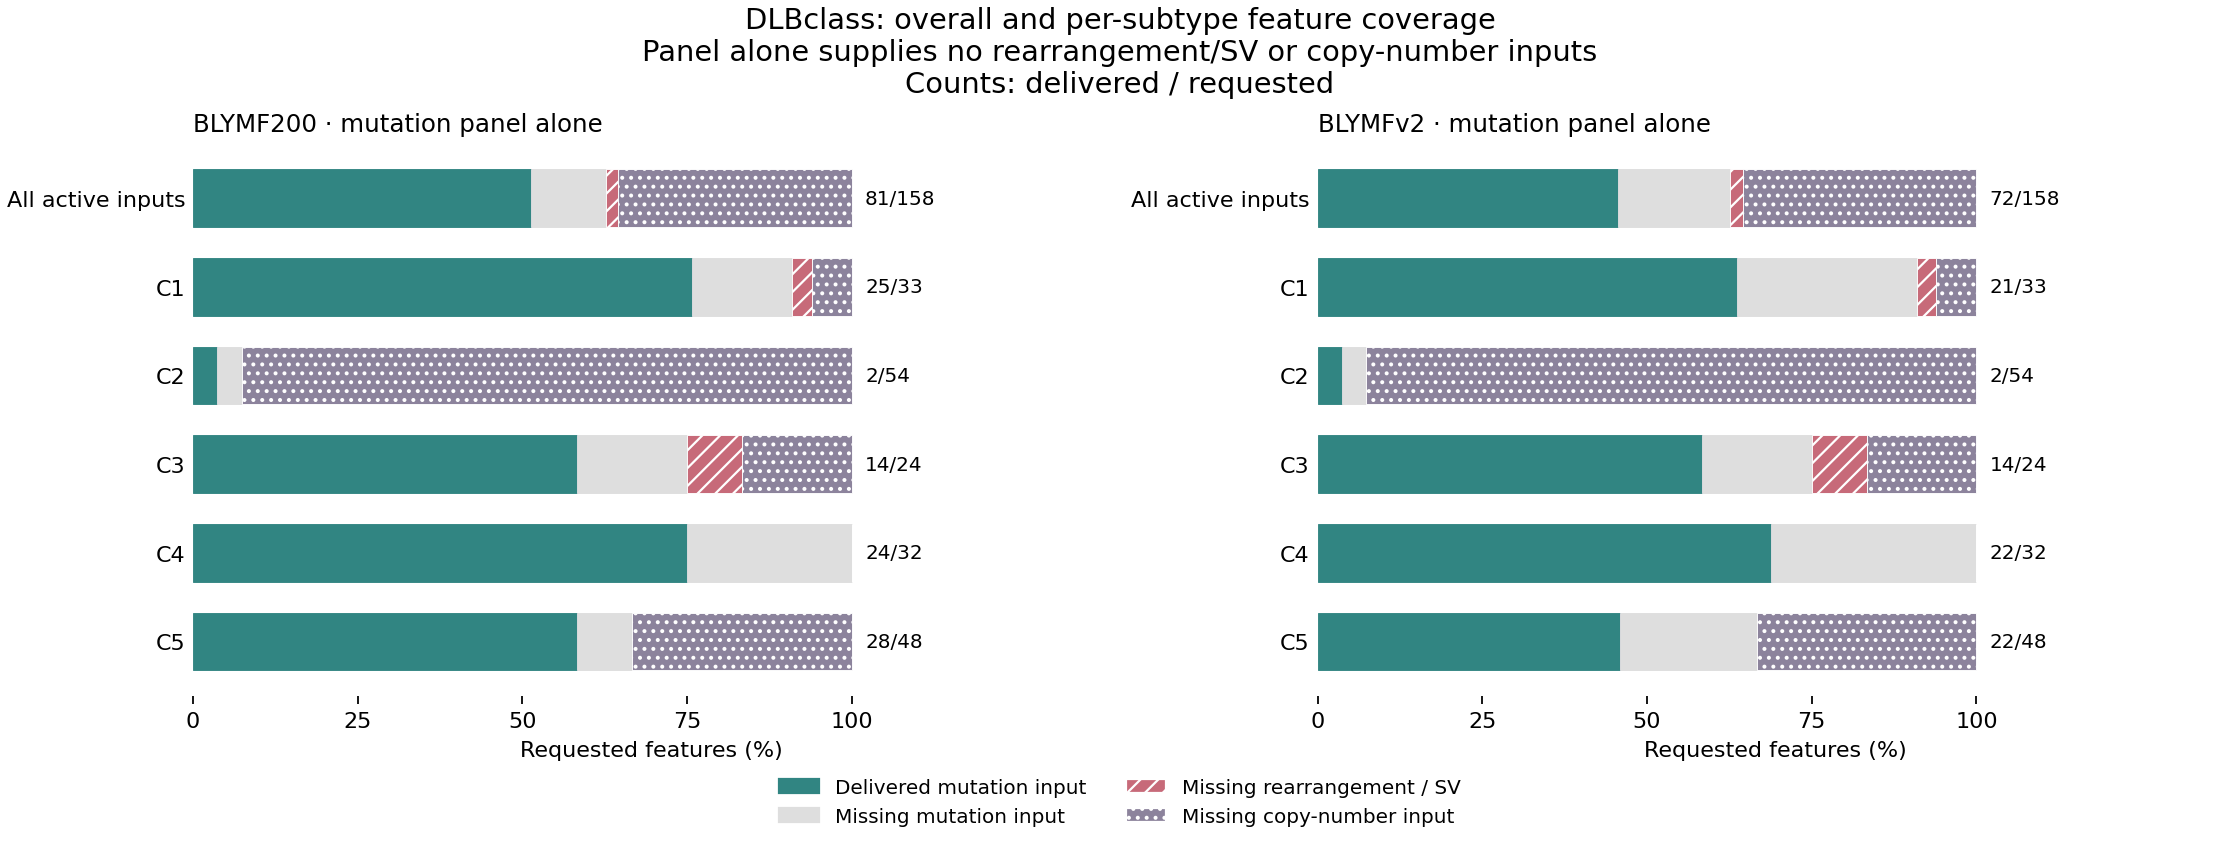

,panel,subtype,All features,Mutation,Rearrangement / SV,Copy-number dependent
25,BLYMF200,C1,25/33,25/30,0/1,0/2
27,BLYMFv2,C1,21/33,21/30,0/1,0/2
29,BLYMF200,C2,2/54,2/4,—,0/50
31,BLYMFv2,C2,2/54,2/4,—,0/50
33,BLYMF200,C3,14/24,14/18,0/2,0/4
35,BLYMFv2,C3,14/24,14/18,0/2,0/4
37,BLYMF200,C4,24/32,24/32,—,—
39,BLYMFv2,C4,22/32,22/32,—,—
41,BLYMF200,C5,28/48,28/32,—,0/16
43,BLYMFv2,C5,22/48,22/32,—,0/16


In [3]:
coverage, design_features = genomic_design_coverage(requirements)
coverage = coverage[coverage.classifier.eq('DLBclass') & coverage.fish.eq('unavailable')]
show_save(plot_subtype_feature_coverage(coverage, 'DLBclass', genomic=True, fish='unavailable'), 'dlbclass_subtype_feature_coverage')
display(subtype_coverage_table(coverage, genomic=True))
coverage.to_csv(OUT / 'dlbclass_subtype_feature_coverage.csv', index=False)


### LymphGen v2 — optional augmentation with separate FISH

This simulation retains BCL2/BCL6 rearrangement calls from the external reference data. These inputs come from the additional FISH assay; the mutation panel still provides no SV or copy-number measurements.

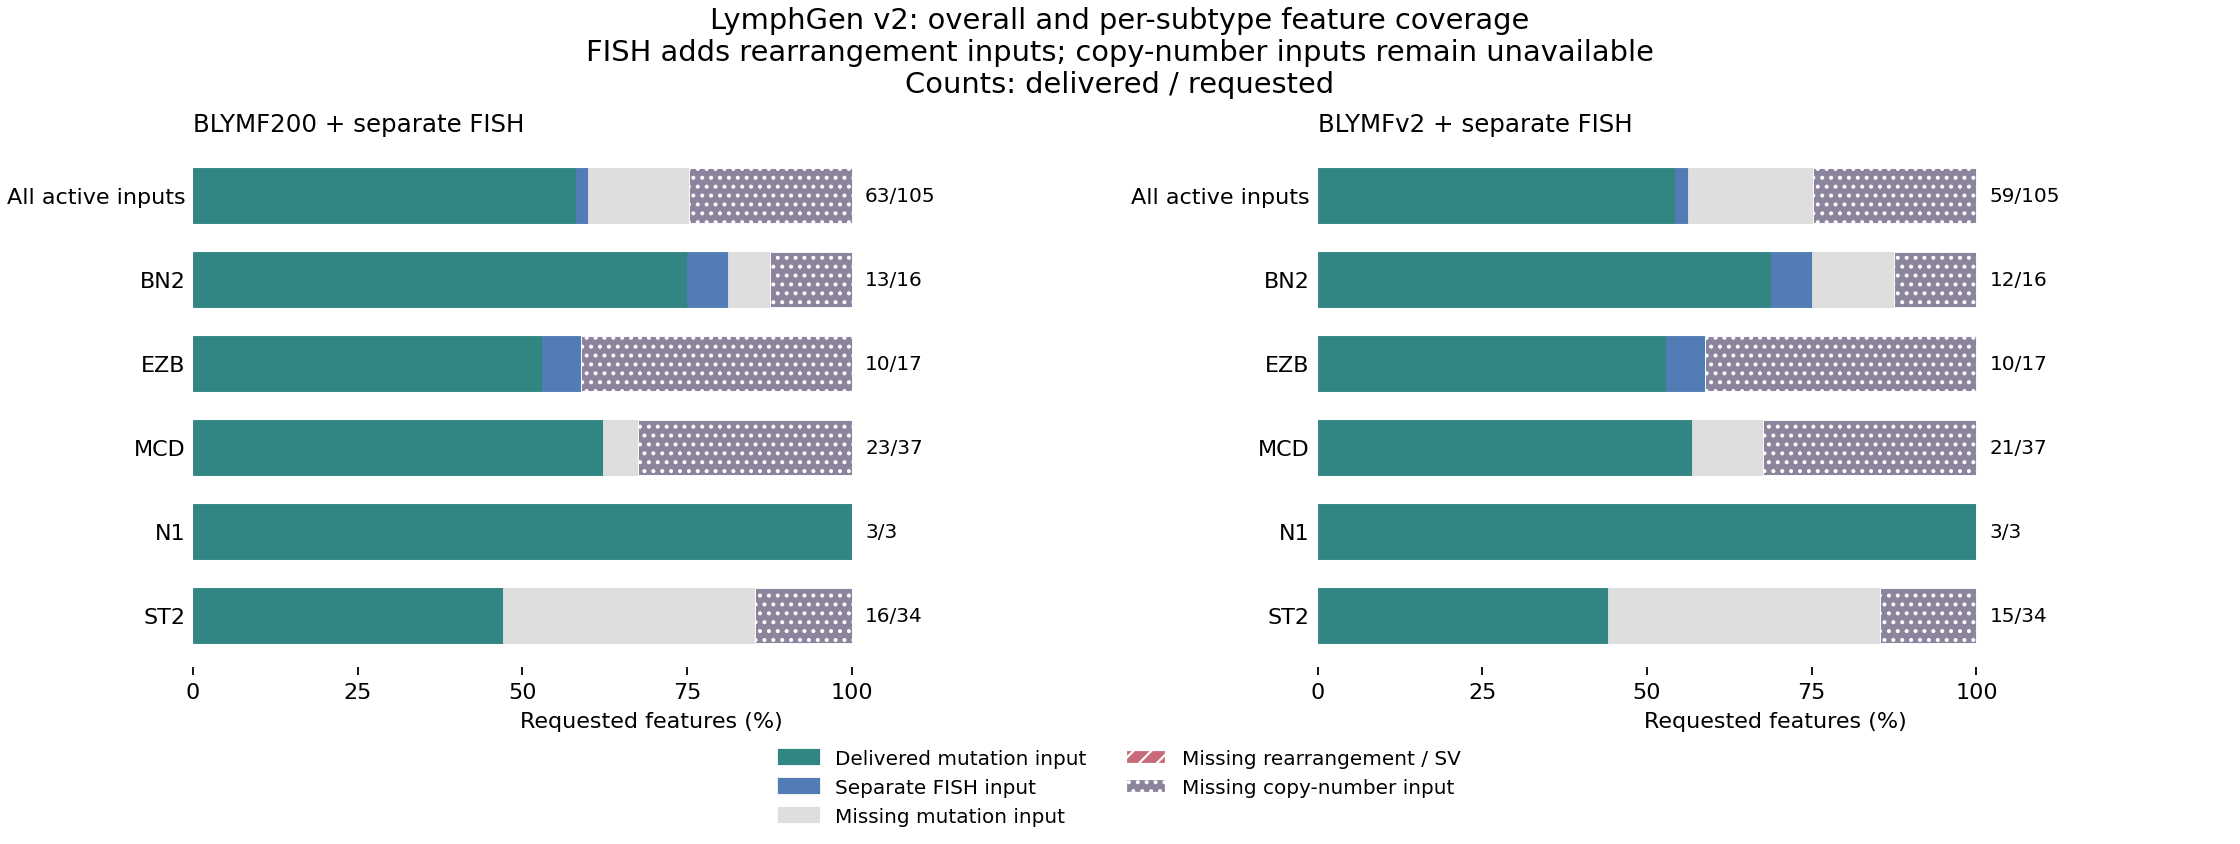

,panel,subtype,All features,Mutation,Rearrangement / SV,Copy-number dependent
0,BLYMF200,BN2,13/16,12/13,1/1,0/2
1,BLYMF200,EZB,10/17,9/9,1/1,0/7
2,BLYMF200,MCD,23/37,23/25,—,0/12
3,BLYMF200,N1,3/3,3/3,—,—
4,BLYMF200,ST2,16/34,16/29,—,0/5
10,BLYMFv2,BN2,12/16,11/13,1/1,0/2
11,BLYMFv2,EZB,10/17,9/9,1/1,0/7
12,BLYMFv2,MCD,21/37,21/25,—,0/12
13,BLYMFv2,N1,3/3,3/3,—,—
14,BLYMFv2,ST2,15/34,15/29,—,0/5


In [4]:
coverage, design_features = genomic_design_coverage(requirements)
coverage = coverage[coverage.classifier.eq('LymphGen v2') & coverage.fish.eq('available')]
show_save(plot_subtype_feature_coverage(coverage, 'LymphGen v2', genomic=True, fish='available'), 'lymphgen_fish_subtype_feature_coverage')
display(subtype_coverage_table(coverage, genomic=True))
coverage.to_csv(OUT / 'lymphgen_fish_subtype_feature_coverage.csv', index=False)


### DLBclass — optional augmentation with separate FISH

Separate MYC/BCL2/BCL6 FISH supplies three rearrangement inputs. All 56 active regional copy-number inputs remain unavailable and imputed.

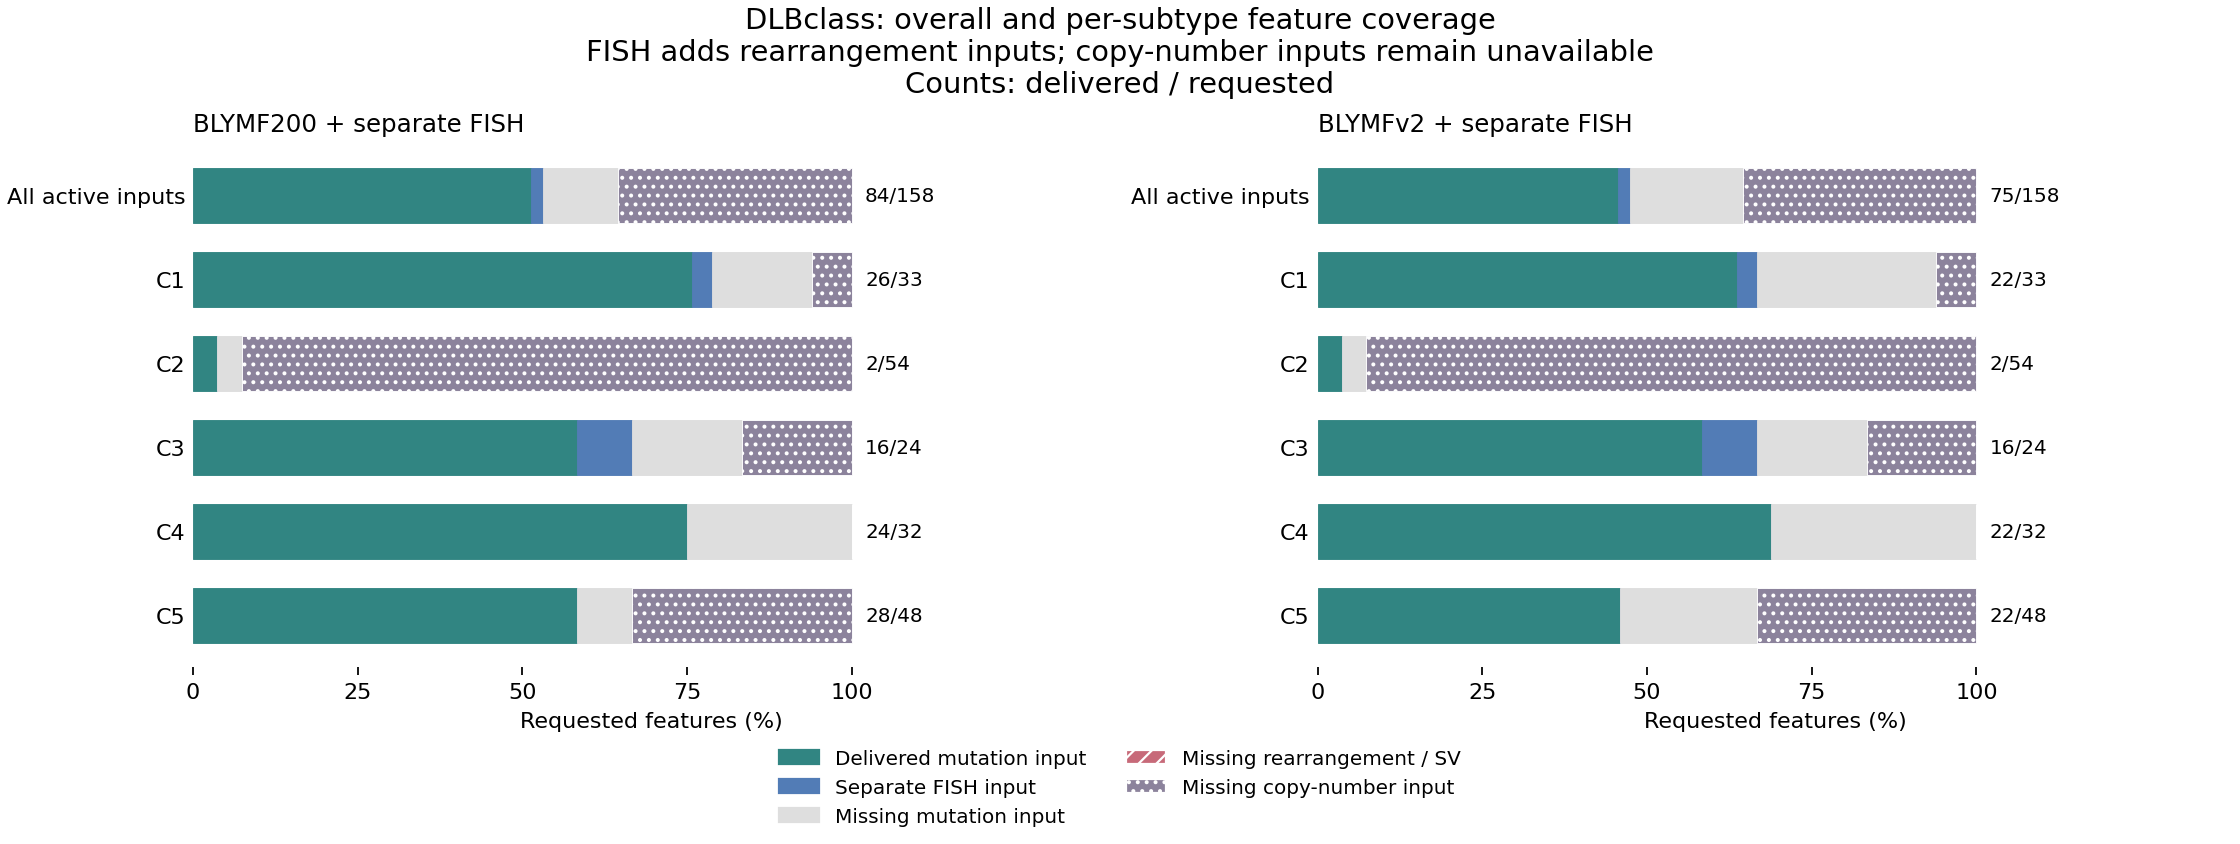

,panel,subtype,All features,Mutation,Rearrangement / SV,Copy-number dependent
24,BLYMF200,C1,26/33,25/30,1/1,0/2
26,BLYMFv2,C1,22/33,21/30,1/1,0/2
28,BLYMF200,C2,2/54,2/4,—,0/50
30,BLYMFv2,C2,2/54,2/4,—,0/50
32,BLYMF200,C3,16/24,14/18,2/2,0/4
34,BLYMFv2,C3,16/24,14/18,2/2,0/4
36,BLYMF200,C4,24/32,24/32,—,—
38,BLYMFv2,C4,22/32,22/32,—,—
40,BLYMF200,C5,28/48,28/32,—,0/16
42,BLYMFv2,C5,22/48,22/32,—,0/16


In [5]:
coverage, design_features = genomic_design_coverage(requirements)
coverage = coverage[coverage.classifier.eq('DLBclass') & coverage.fish.eq('available')]
show_save(plot_subtype_feature_coverage(coverage, 'DLBclass', genomic=True, fish='available'), 'dlbclass_fish_subtype_feature_coverage')
display(subtype_coverage_table(coverage, genomic=True))
coverage.to_csv(OUT / 'dlbclass_fish_subtype_feature_coverage.csv', index=False)


In [6]:
design_coverage, design_features = genomic_design_coverage(requirements)
design_coverage.to_csv(OUT / 'declared_panel_coverage.csv', index=False)
design_features.to_csv(OUT / 'declared_panel_feature_list.csv', index=False)

## External-data performance benchmarks

The panel-design audit above is complete without cohort data. The following cells load external benchmark results to assess call retention, recall/precision and sample-level input availability. Missing genes in an external matrix do not change the declared panel coverage.

In [7]:
ADATA_PATH = ROOT / 'data/public/panel_call_confidence.public.h5ad'
adata = load_public_adata(ADATA_PATH)

,classifier,panel,fish,n,n_matching,exact_label_agreement
0,DLBclass,BLYMF200,available,149,116,0.778523
1,DLBclass,BLYMF200,unavailable,149,111,0.744966
2,DLBclass,BLYMFv2,available,149,112,0.751678
3,DLBclass,BLYMFv2,unavailable,149,108,0.724832
4,LymphGen v2,BLYMF200,available,574,512,0.891986
5,LymphGen v2,BLYMF200,unavailable,574,484,0.843206
6,LymphGen v2,BLYMFv2,available,574,505,0.879791
7,LymphGen v2,BLYMFv2,unavailable,574,481,0.837979


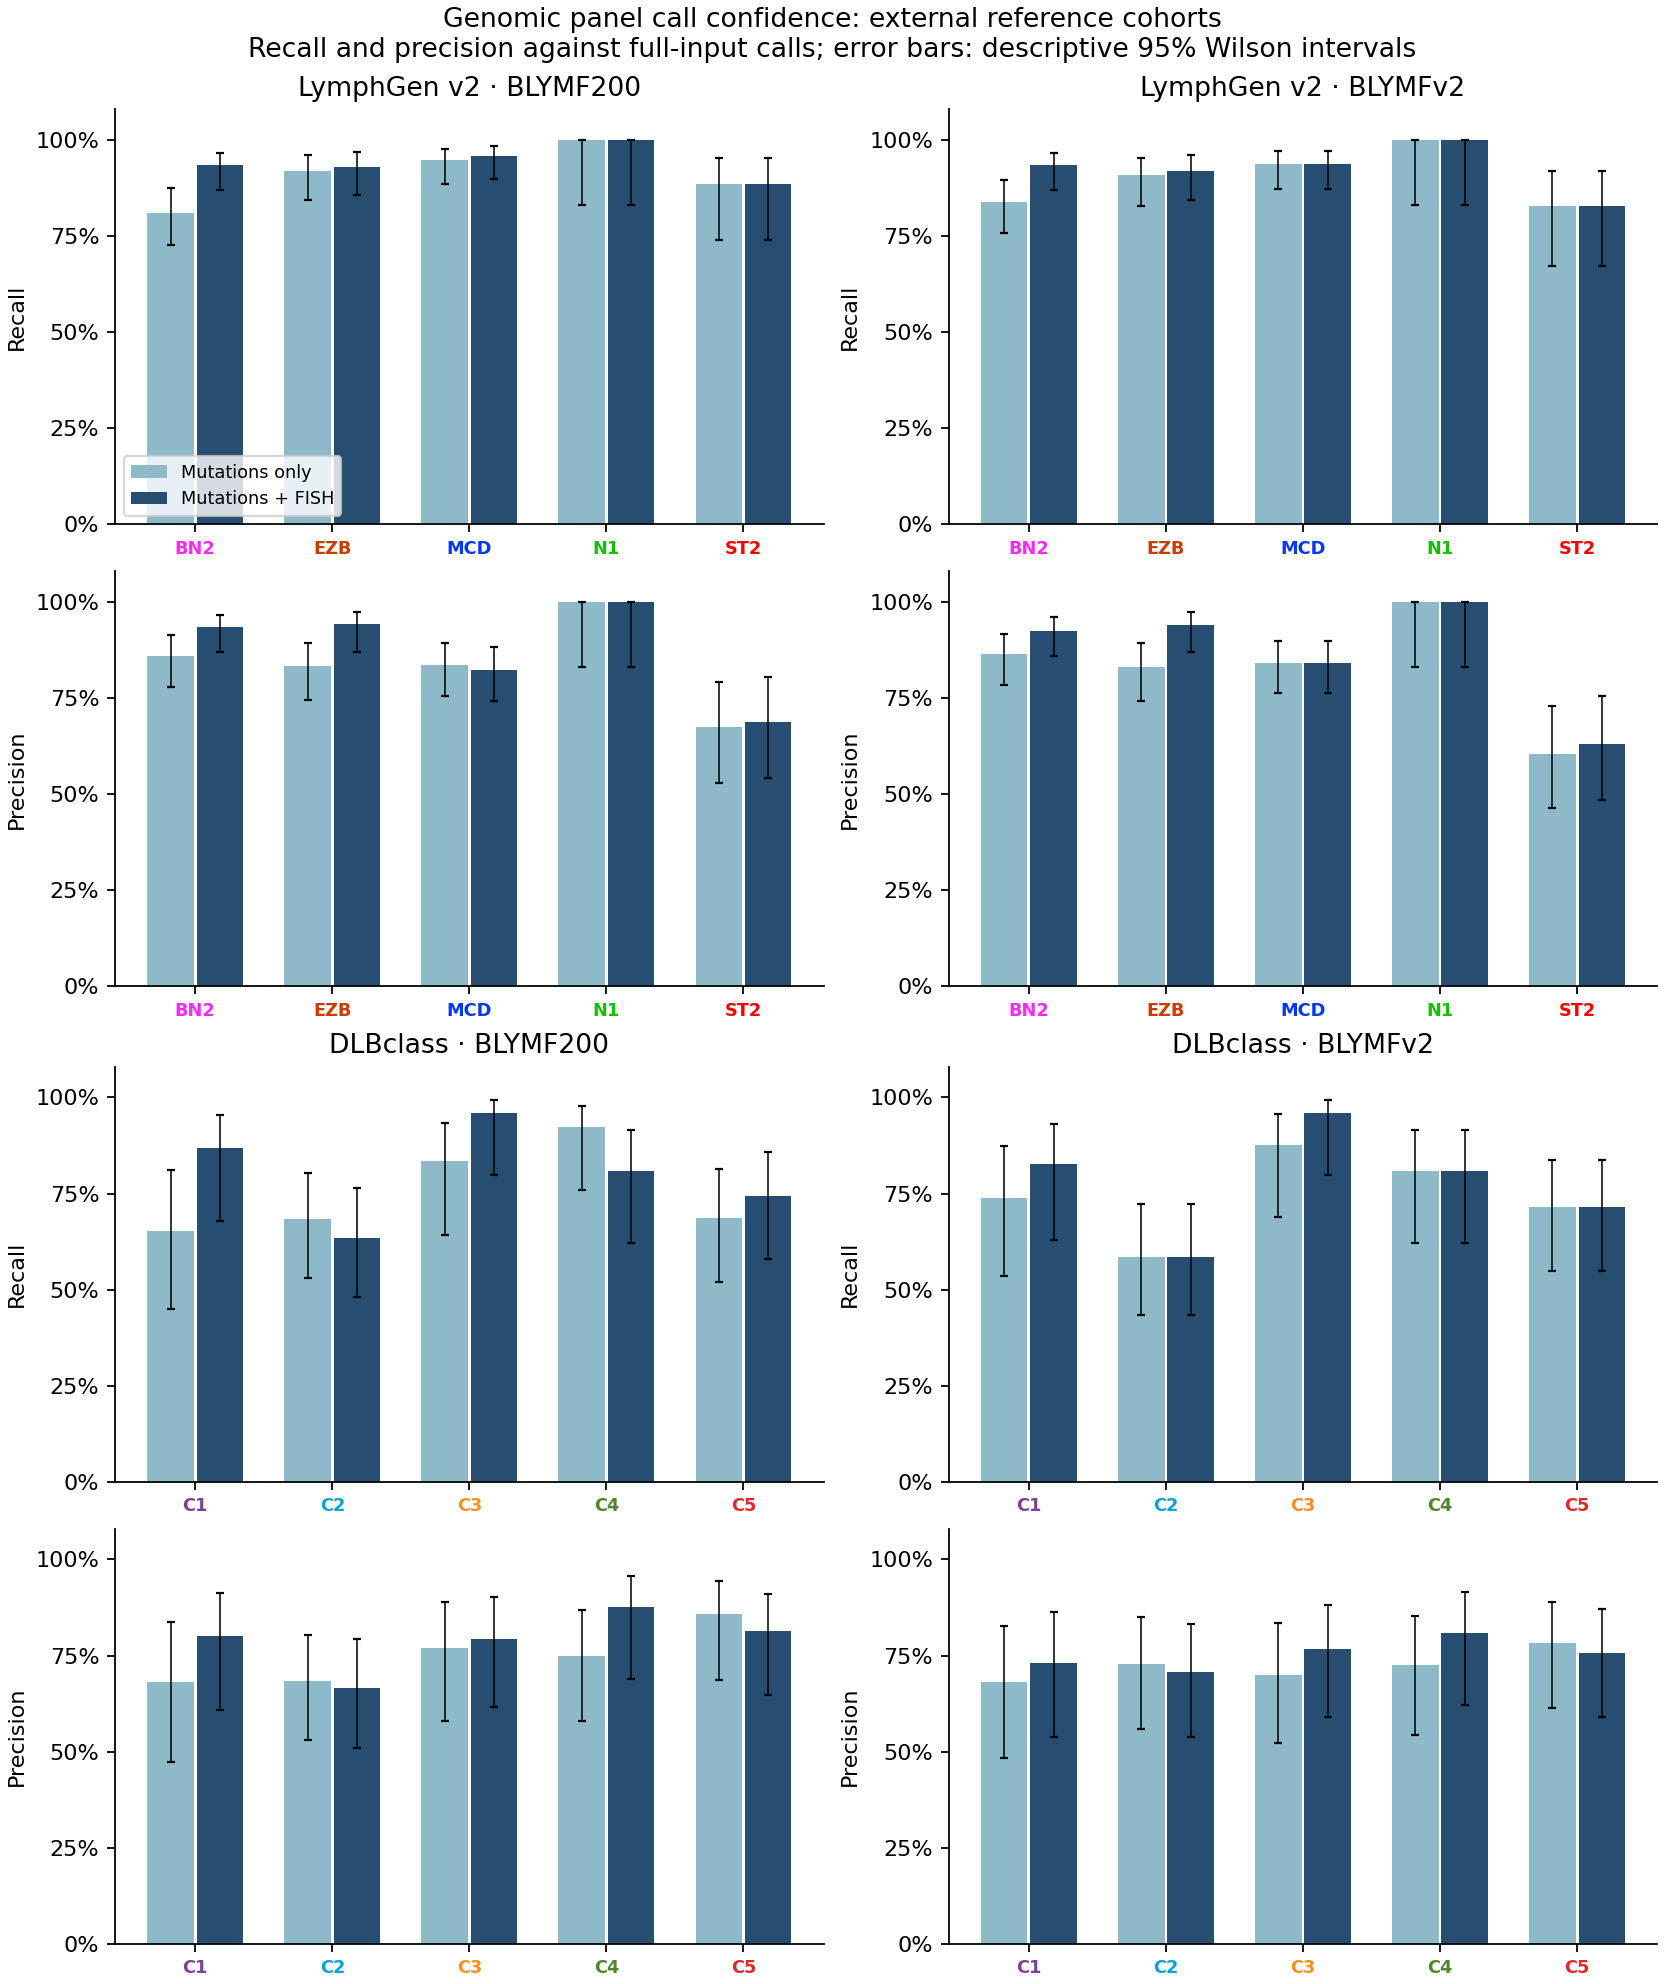

In [8]:
PANELS = ['BLYMF200', 'BLYMFv2']
CLASSIFIERS = ['LymphGen v2', 'DLBclass']
counts = table(adata, 'genomic', 'counts', 'LymphGen')
counts = counts[counts.panel.isin(PANELS) & counts.classifier.isin(CLASSIFIERS)]
metrics = metrics_from_counts(counts, full='reference_n', panel='predicted_n')
metrics.to_csv(OUT / 'per_subtype_confidence.csv', index=False)
display(table(adata, 'genomic', 'overall', 'DLBclass'))
show_save(plot_bars(metrics, CLASSIFIERS, PANELS, genomic=True,
                   label_colors=LABEL_COLORS, title='Genomic panel call confidence: external reference cohorts'), 'recall_precision')

## Direction of call changes

Rows are full-feature calls and columns are panel-restricted calls. Cells show counts and row percentages. Exact composite labels remain separate here, so a diagonal entry reflects exact-label agreement. This differs from subtype membership recall/precision, where each constituent subtype is counted separately. Zero-denominator metrics are undefined (`NA`), not zero.

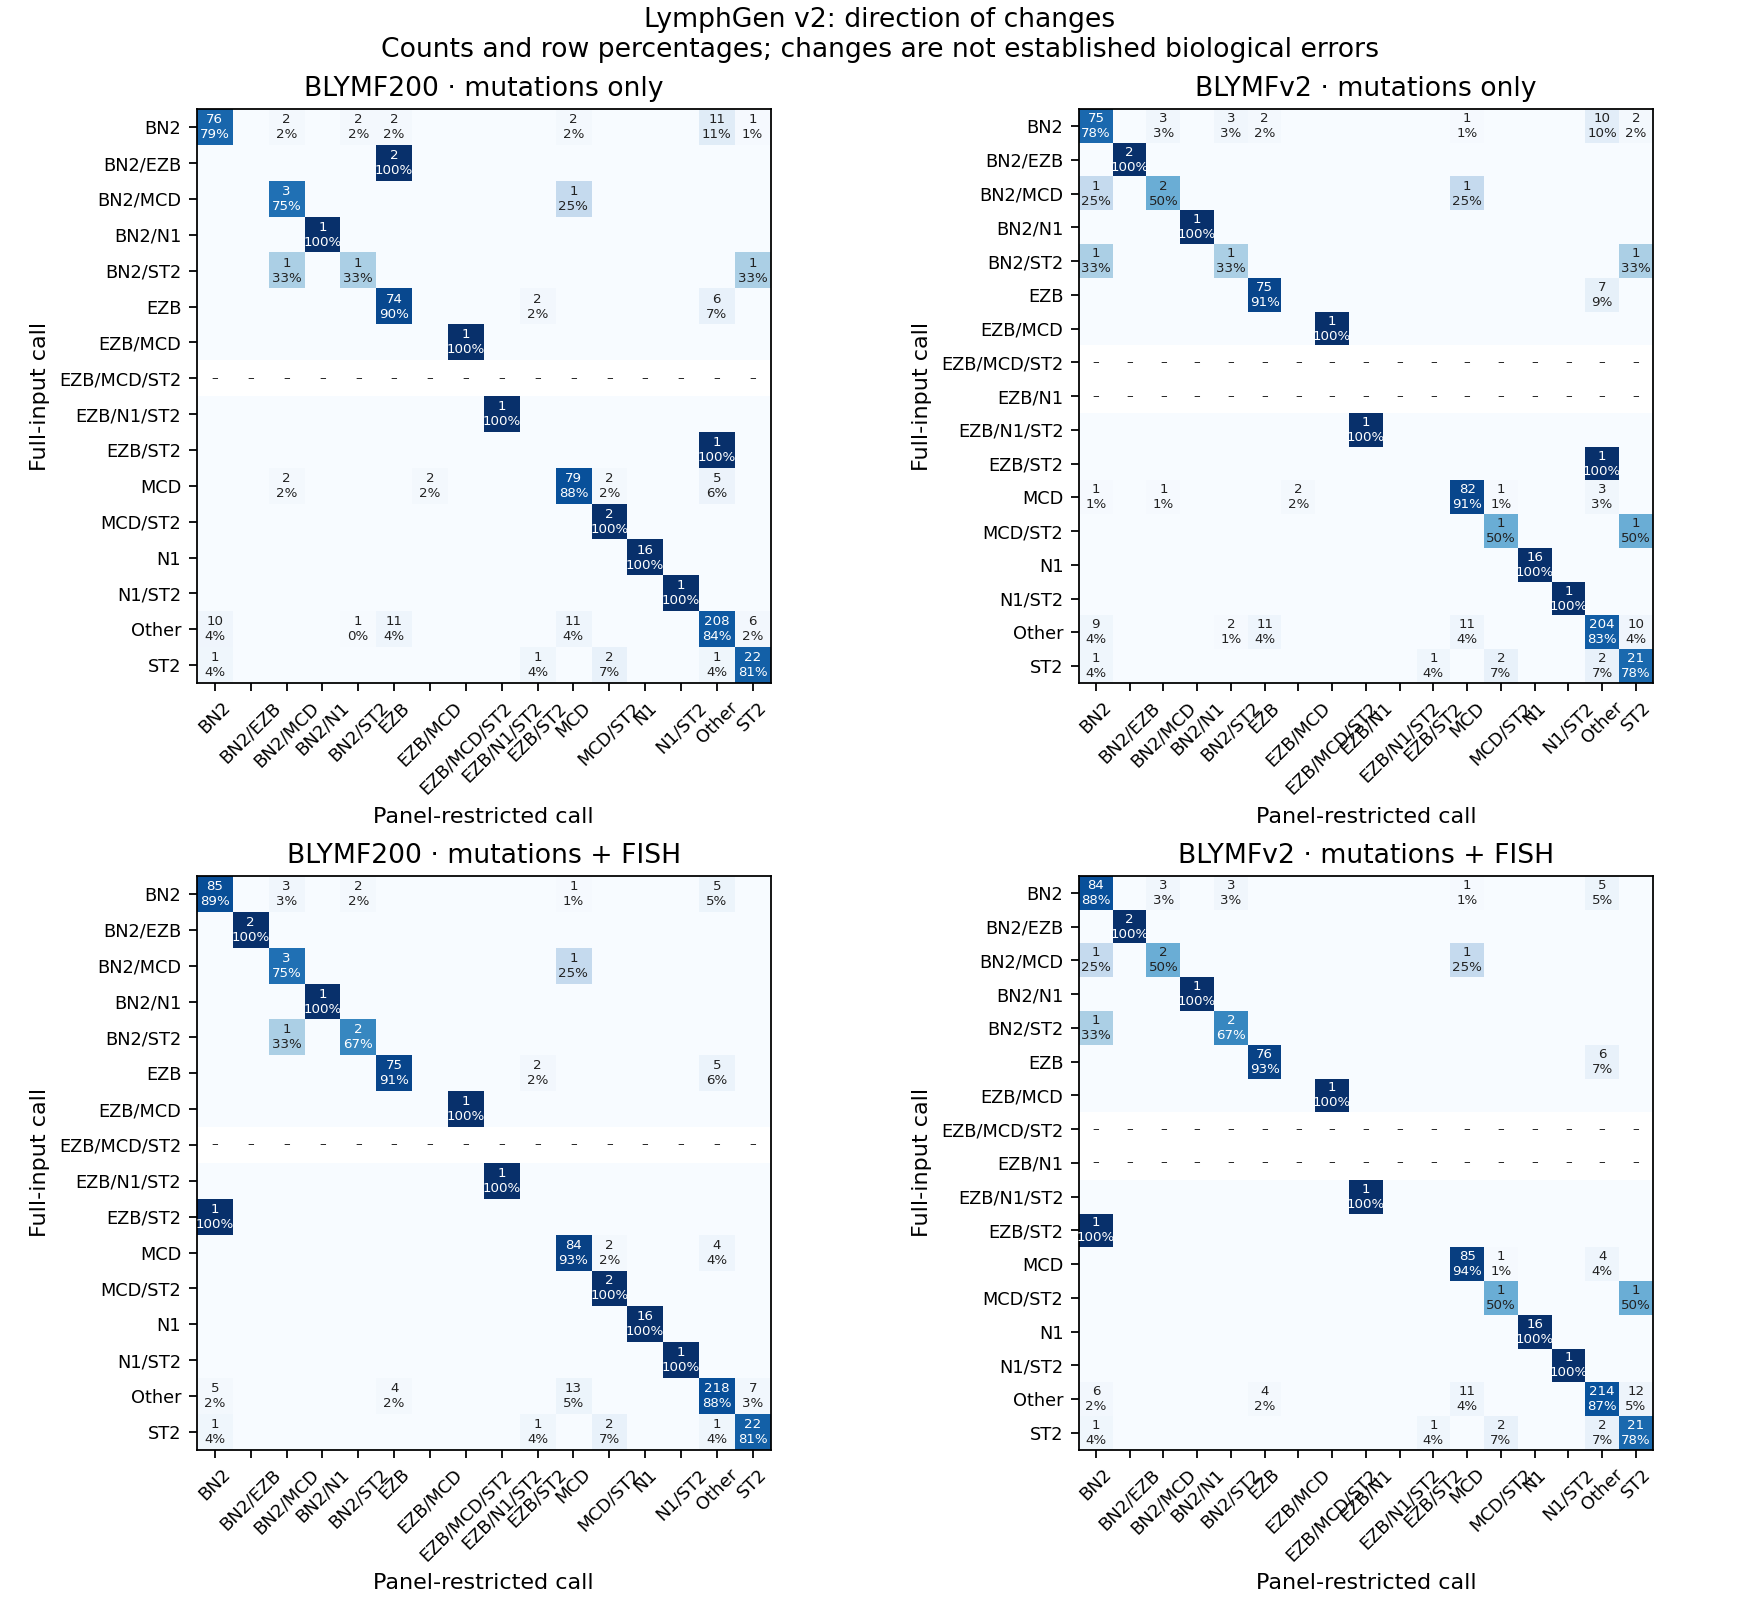

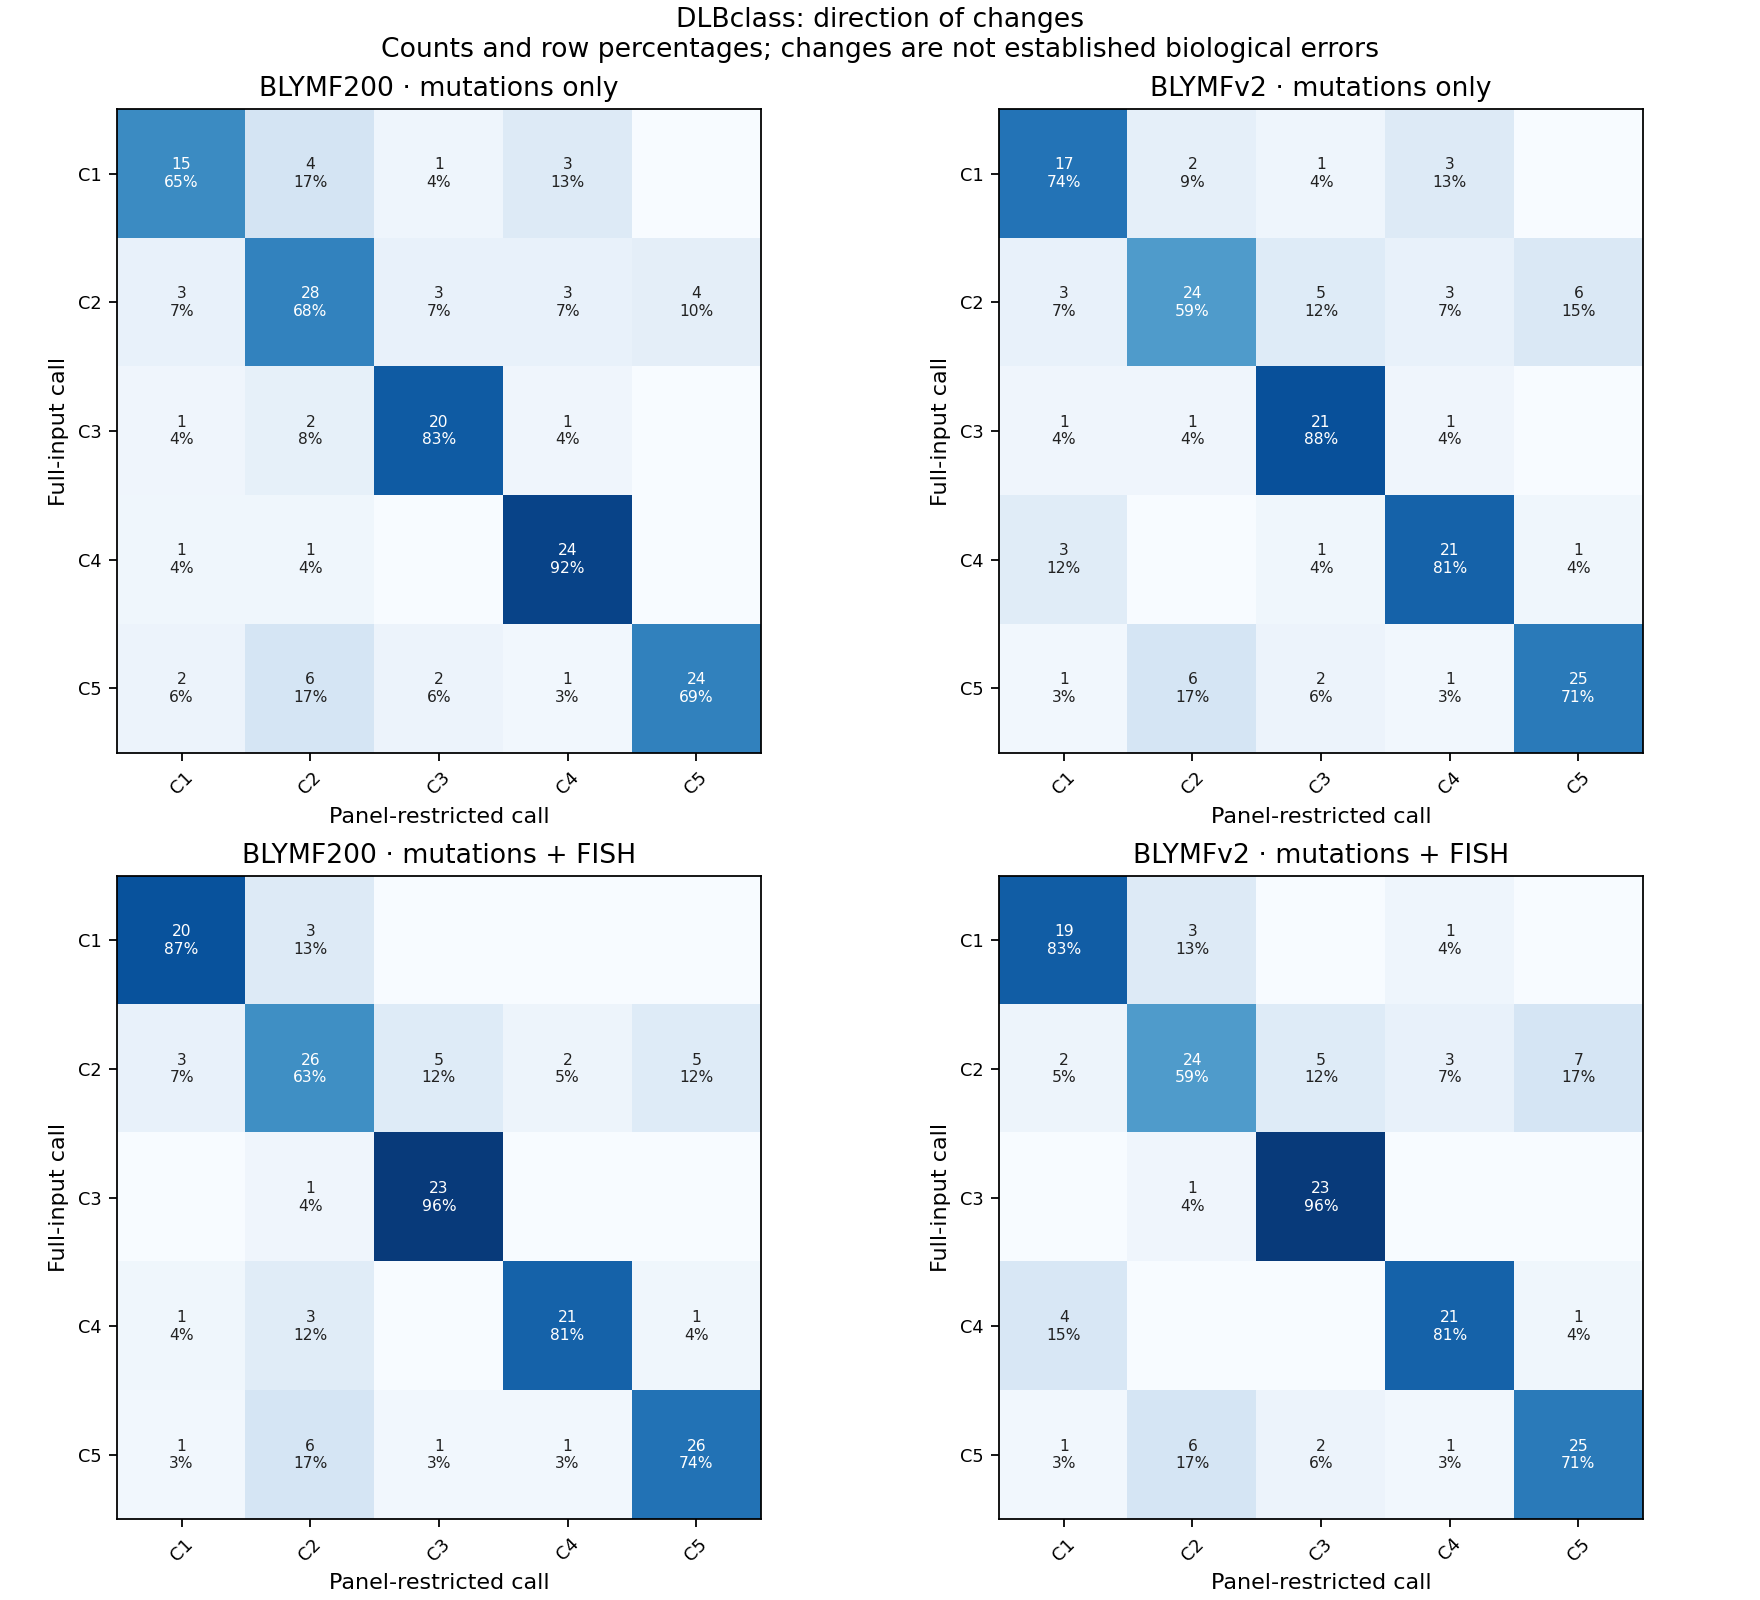

,classifier,panel,fish,subtype,reference_n,predicted_n,tp,fp,fn,recall,recall_low,recall_high,precision,precision_low,precision_high
0,LymphGen v2,BLYMF200,unavailable,BN2,106,100,86,14,20,0.811,0.726,0.874,0.860,0.779,0.915
1,LymphGen v2,BLYMF200,unavailable,EZB,87,96,80,16,7,0.920,0.843,0.960,0.833,0.746,0.895
2,LymphGen v2,BLYMF200,unavailable,MCD,97,110,92,18,5,0.948,0.885,0.978,0.836,0.756,0.894
3,LymphGen v2,BLYMF200,unavailable,N1,19,19,19,0,0,1.000,0.832,1.000,1.000,0.832,1.000
4,LymphGen v2,BLYMF200,unavailable,ST2,35,46,31,15,4,0.886,0.740,0.955,0.674,0.530,0.791
5,LymphGen v2,BLYMF200,available,BN2,106,106,99,7,7,0.934,0.870,0.968,0.934,0.870,0.968
6,LymphGen v2,BLYMF200,available,EZB,87,86,81,5,6,0.931,0.858,0.968,0.942,0.871,0.975
7,LymphGen v2,BLYMF200,available,MCD,97,113,93,20,4,0.959,0.899,0.984,0.823,0.742,0.882
8,LymphGen v2,BLYMF200,available,N1,19,19,19,0,0,1.000,0.832,1.000,1.000,0.832,1.000
9,LymphGen v2,BLYMF200,available,ST2,35,45,31,14,4,0.886,0.740,0.955,0.689,0.543,0.805


In [9]:
transitions = table(adata, 'genomic', 'transitions', 'LymphGen')
transitions = transitions[transitions.panel.isin(PANELS)]
for classifier in CLASSIFIERS:
    show_save(plot_transitions(transitions, classifier, PANELS, genomic=True),
              classifier.lower().replace(' ', '_') + '_transitions')
transitions.to_csv(OUT / 'exact_transitions.csv', index=False)
display(metrics.round(3))

## Source data availability

The default figures regenerate metrics from **released aggregate external benchmark counts**. Full model inference for LymphGen, DLBclass, LymphoMAP, EcoTyper, Kotlov and Ciavarella is not rerun by these plotting cells. Their reference cohorts and methods are documented above. The transcriptomic notebook does recompute the full Lymph2Cx model and cross-validation from the included public NanoString counts.

The source inventory distinguishes publicly included matrices, publicly available upstream datasets not bundled here, and exact source matrices not redistributed. A missing source is never silently replaced. Requesting a nonredistributed source raises `SourceDataUnavailableError`: **“The source data cannot be released with this public AnnData bundle”**, followed by the relevant paper and access route. Public datasets missing from the bundle instead get a public-download message; absence does not imply that the original dataset is legally restricted.

To inspect a source, set `SOURCE_TO_LOAD` below. Leaving it `None` generates figures from the bundled benchmark tables.

In [10]:
SOURCE_TO_LOAD = None  # Choose one of ['LymphGen', 'DLBclass'] to load its original source matrix.
inventory = pd.DataFrame.from_dict(SOURCES, orient='index').loc[['LymphGen', 'DLBclass']]
display(inventory[['paper', 'citation', 'status', 'access', 'note']])
if SOURCE_TO_LOAD is not None:
    source_matrix = require_source(adata, SOURCE_TO_LOAD)  # Deliberate hard error if unavailable.
    display(source_matrix.iloc[:5, :5])


,paper,citation,status,access,note
LymphGen,"Wright et al., Cancer Cell 2020, LymphGen",https://doi.org/10.1016/j.ccell.2020.03.015,source_not_bundled,https://llmpp.nih.gov/lymphgen/index.php,Author-reference benchmark aggregates are incl...
DLBclass,"Chapuy et al., Blood 2025, DLBclass",https://doi.org/10.1182/blood.2024025652,public_matrix_included,https://github.com/getzlab/DLBCL-Classifier,Public encoded 699-case gene-sample matrix; or...


## Reproducibility

All required aggregate inputs are embedded in the accompanying public AnnData. The public DLBclass encoded feature matrix and the classifier feature inventories are included. The loader checks the bundle schema and registered reference cohorts before reading the analysis tables. Source hashes and methodological limitations are retained in the provenance. Figures and numeric tables are written to `figures/genomic_panel_call_confidence/`.

In [11]:
display(json.loads(adata.uns['provenance_json']))
print('Figures and tables:', OUT.relative_to(ROOT))

{'scope': 'External reference data and aggregate derived benchmarks only',
 'expression_sources_included': ['GSE178394: 20 measured classifier genes'],
 'genomic_sources_included': ['DLBclass: author-public 699-case encoded feature matrix'],
 'study_data_included': False,
 'raw_inference': 'Only Lymph2Cx is recomputed in these notebooks; other figures use archived external benchmark counts',
 'external_cohorts': ['Schmitz', 'Morin', 'Li', 'Chapuy', 'GSE178394'],
 'source_sha256': {'aligned_metrics.csv': '3f090340bac6708d859cec4b44c898f605b0a3239fcbd982ec94a8c8ad32a67c',
  'reference_pairs.csv': 'ba517f59af9d336bb9276ccc1616fdf6f4641533c1434b1baff65113048aca20',
  'overall_agreement.csv': '7a31753df6acbf9a7e3324c547a511122be40cac3b86dc8818b77dacc1e66350',
  'per_subtype_metrics.csv': '0dfe6a28af9749c5c32a952988c3ab4e29e762184f3e18860ddb1323a8379e27',
  'directional_transitions.csv': 'd9e5389bf16239483cb30e5930459f17d2f742addd9eb6db9655756e34de3fb7',
  'clustering_per_label_metrics.csv':

Figures and tables: figures/genomic_panel_call_confidence
